# Group Homework 3 · The GoMart report makeover
**Data Visualization · UEH · Session 3** · team notebook

| | |
|---|---|
| **Team** | *team name* · **team number** (from the LMS list): __ |
| **Status** | Formative: written feedback with the rubric in the brief. Task 0 is the first version of Module M3 of your project |
| **Submit** | File ▸ Download ▸ .ipynb as `GH3_TeamName.ipynb` + the evidence folder of Task 4, within 7 days on the LMS |

Read the brief *Group Homework 3* first. All GoMart data is simulated.

## Task 5 · One-page summary for the operations director (write this last)
**Big Idea:** *one complete sentence.*

*At most 100 words. The one-page figure is made in the last code cell of the notebook (it needs everything above);
after "Restart and run all", paste its image here.*

## Task 0 · Project: house style v0 and makeover plan (Module M3)
**Allocated project:** P__ · *title*

1. Put your `house_style.py` v0 in the cell below (palette in fixed order, sequential map, diverging map, fonts, number format).
2. Show the evidence: a swatch of your palette in colour, in greyscale and with simulated deuteranopia.
3. Makeover plan for one published chart from your domain: link, screenshot, critique table, photo of your hand sketch.

In [ ]:
# Task 0 · house_style.py v0 for your project (paste the file content here, then run it)
# PROJECT_PALETTE = [...]       # fixed order, one colour per category of your project
# SEQ_CMAP = "..."; DIV_CMAP = "..."
# def use_house_style(): ...

In [ ]:
# Task 0 · evidence: palette swatch in colour, greyscale, deuteranopia
# (use fig_to_rgb, to_grey and simulate_cvd from the Setup section below)

**Makeover plan.** Source (link, date accessed): ...

| # | What I see | Principle broken (name it) | Effect on the reader | My fix |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |

*Insert the photo of your hand sketch here.*

## Setup
Upload `gomart_orders_2025_clean.csv`, `gomart_districts.csv` and `gomart_targets_2025.csv`.
Run `gomart_bad_report.py` once (or open `gomart_bad_report.pdf`) to see the six charts you will audit.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import TwoSlopeNorm, to_rgb

GREY, LIGHT, DARK, BLUE, ORANGE = "#a3a29c", "#d9d8d3", "#52514e", "#2a78d6", "#eb6834"
ZONE_COLOR = {"Central": "#a9c9ef", "Inner": "#5b9be3", "Outer": "#1f4f8f"}   # ordered: light -> dark

In [ ]:
orders = pd.read_csv("gomart_orders_2025_clean.csv", parse_dates=["order_time"])
districts = pd.read_csv("gomart_districts.csv")
targets = pd.read_csv("gomart_targets_2025.csv")
orders = orders.merge(districts, on="district", how="left", validate="many_to_one")
orders["month"] = orders["order_time"].dt.strftime("%Y-%m")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
orders["weekday"] = pd.Categorical(orders["order_time"].dt.strftime("%a"), categories=days, ordered=True)
orders["hour"] = orders["order_time"].dt.hour
tiers = ["none", "Silver", "Gold", "Platinum"]
orders["member_tier"] = pd.Categorical(orders["member_tier"], categories=tiers, ordered=True)
delivered = orders[orders["status"] == "delivered"]
print(orders.shape, "| orders without zone:", orders["zone"].isna().sum())

Helper functions from Tutorial 3 (given):

In [ ]:
def fig_to_rgb(fig):
    fig.canvas.draw()
    return np.asarray(fig.canvas.buffer_rgba())[..., :3] / 255

def to_grey(rgb):
    return np.asarray(rgb)[..., :3] @ np.array([0.299, 0.587, 0.114])

DEUTAN = np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413],
                   [-0.011820, 0.042940, 0.968881]])

def simulate_cvd(rgb, M=DEUTAN):
    lin = np.where(rgb <= 0.04045, rgb / 12.92, ((rgb + 0.055) / 1.055) ** 2.4)
    sim = np.clip(lin @ M.T, 0, 1)
    return np.where(sim <= 0.0031308, 12.92 * sim, 1.055 * sim ** (1 / 2.4) - 0.055)

## Task 1 · Audit the report
For each of the six charts: the task the chart should support (action + target), then at least four problems.

| Chart | Task it should support | Problem | Principle (name it) | Effect on the reader |
|---|---|---|---|---|
| 1 Orders by district | | | | |
| 1 | | | | |
| 2 Payments | | | | |
| ... | | | | |

## Task 2 · Redesign
### Chart 1 · Orders by district
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 2 · Payments
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 3 · Delivery time
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

In [ ]:
# TODO: write your code here

### Chart 4 · Peak times
*Task:* ...  *Why this chart:* ...

In [ ]:
# TODO: write your code here

### Chart 5 · Targets
**Task:** Compare monthly actual orders against targets for Central, Inner, and Outer zones to identify underperforming months.

**Why this chart:** Three aligned diverging bar charts with a shared Y-axis enable accurate comparisons across zones. A zero reference line and signed value labels make shortfalls and surpluses easy to identify.

In [1]:

# Chart 5 - Data preparation
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find the data folder
candidates = [
    Path("data/raw"),
    Path("../../data/raw"),
    Path.cwd() / "data/raw",
]

data_dir = next(
    (p for p in candidates if
     (p / "gomart_targets_2025.csv").exists()),
    None
)
if data_dir is None:
    raise FileNotFoundError("Cannot find data/raw")

orders5 = pd.read_csv(
    data_dir / "gomart_orders_2025_clean.csv",
    parse_dates=["order_time"]
)
districts5 = pd.read_csv(
    data_dir / "gomart_districts.csv"
)
targets5 = pd.read_csv(
    data_dir / "gomart_targets_2025.csv"
)

# Join orders with their zones
orders5 = orders5.merge(
    districts5[["district", "zone"]],
    on="district",
    how="left",
    validate="many_to_one"
)
orders5["month"] = orders5["order_time"].dt.strftime("%Y-%m")

# Count monthly orders by zone
actual5 = (
    orders5.groupby(["zone", "month"])
    .size()
    .reset_index(name="actual_orders")
)

# Compare actual orders with targets
chart5 = targets5.merge(
    actual5,
    on=["zone", "month"],
    how="left",
    validate="one_to_one"
)

chart5["actual_orders"] = (
    chart5["actual_orders"].fillna(0).astype(int)
)
chart5["gap"] = (
    chart5["actual_orders"] - chart5["target_orders"]
)

zone_order5 = ["Central", "Inner", "Outer"]
chart5["zone"] = pd.Categorical(
    chart5["zone"],
    categories=zone_order5,
    ordered=True
)
chart5 = chart5.sort_values(["zone", "month"])

assert len(chart5) == 36
assert chart5["zone"].notna().all()

print(chart5.to_string(index=False))
print("\nTotal gap by zone:")
print(chart5.groupby("zone", observed=True)["gap"].sum())


   zone   month  target_orders  actual_orders  gap
Central 2025-01            116            110   -6
Central 2025-02            117            105  -12
Central 2025-03            123            131    8
Central 2025-04            125            143   18
Central 2025-05            125            137   12
Central 2025-06            136            137    1
Central 2025-07            137            101  -36
Central 2025-08            143            145    2
Central 2025-09            151            122  -29
Central 2025-10            151            123  -28
Central 2025-11            151            133  -18
Central 2025-12            157            132  -25
  Inner 2025-01            196            181  -15
  Inner 2025-02            192            177  -15
  Inner 2025-03            205            240   35
  Inner 2025-04            211            214    3
  Inner 2025-05            211            223   12
  Inner 2025-06            223            220   -3
  Inner 2025-07            232 

### Chart 5 – Targets: Audit

**Task:** Identify which zones and months missed their order targets in 2025.

| Problem | Violated principle | Effect on the reader |
|---|---|---|
| Different Y-axis scales across zones | Effectiveness | Readers may misjudge the relative size of target gaps. |
| Red and green bars indicate performance | Colour-vision deficiency | Some readers may struggle to distinguish positive and negative gaps. |
| Generic title without a takeaway | Preattentive attention | Readers must inspect all three panels to find the most important result. |
| Important shortfalls are not highlighted | Effectiveness | The largest negative gaps are difficult to identify quickly. |
| Repeated labels and unnecessary borders | Data-ink | Visual clutter reduces readability. |

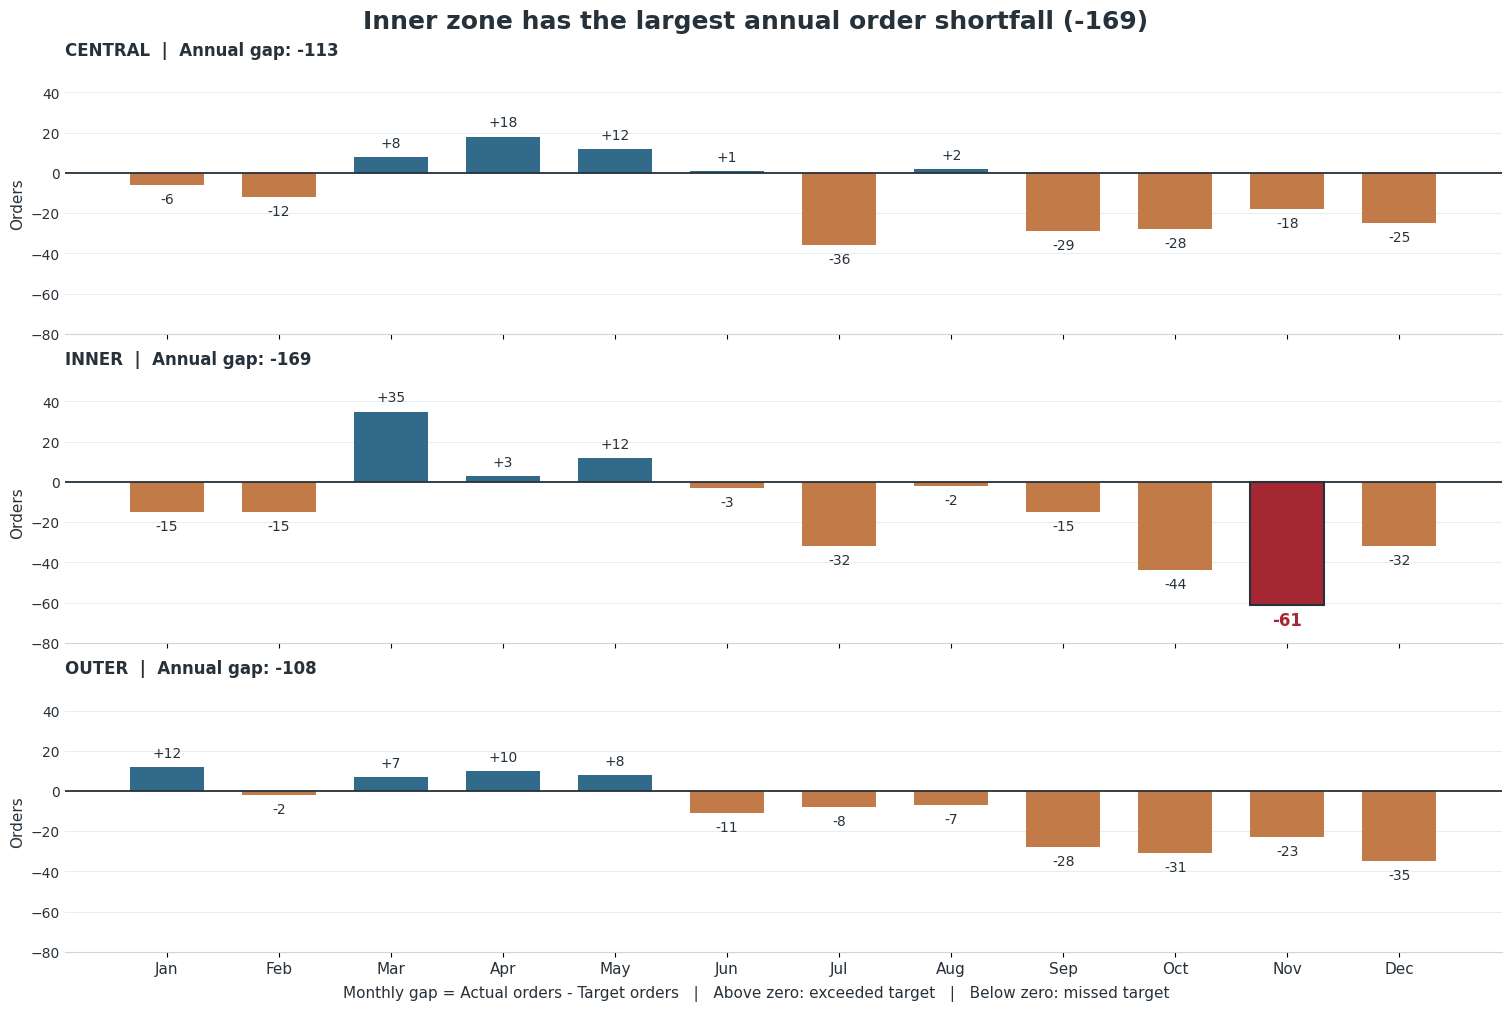

In [2]:

# ============================================================
# CHART 5 - FINAL REDESIGN | GoMart Operations Report 2025
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Data from Chart 5 preparation cell
months5 = sorted(chart5["month"].unique())
x5 = np.arange(len(months5))

# Accessible color palette
POS = "#326A8A"       # Above target
NEG = "#C17A48"       # Below target
FOCUS = "#A52734"     # Largest monthly shortfall
TEXT = "#27313A"
GRID = "#E8EDF0"

# Automatically identify the largest monthly shortfall
worst5 = chart5.loc[chart5["gap"].idxmin()]
worst_zone5 = str(worst5["zone"])
worst_month5 = str(worst5["month"])
worst_gap5 = int(worst5["gap"])

# Annual gap by zone
annual5 = (
    chart5.groupby("zone", observed=True)["gap"]
    .sum()
)
annual_worst5 = annual5.idxmin()
annual_gap5 = int(annual5.min())

# Shared Y-axis range for fair comparisons
ymin5 = min(-80, int(chart5["gap"].min()) - 10)
ymax5 = max(50, int(chart5["gap"].max()) + 10)

fig5, axes5 = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharex=True,
    sharey=True,
    constrained_layout=True
)

for ax, zone in zip(axes5, zone_order5):

    subset = chart5[chart5["zone"] == zone]

    values = (
        subset.set_index("month")
        .reindex(months5)["gap"]
        .to_numpy()
        .astype(int)
    )

    colors = [
        FOCUS if (
            zone == worst_zone5
            and month == worst_month5
        )
        else POS if value >= 0 else NEG
        for month, value in zip(months5, values)
    ]

    bars = ax.bar(
        x5, values,
        width=0.66,
        color=colors,
        zorder=3
    )

    # Zero reference line
    ax.axhline(
        0,
        color=TEXT,
        linewidth=1.3,
        zorder=4
    )

    ax.set_ylim(ymin5, ymax5)

    # Zone heading with annual gap
    ax.set_title(
        f"{zone.upper()}  |  Annual gap: {int(annual5[zone]):+d}",
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=TEXT,
        pad=12
    )

    ax.set_ylabel(
        "Orders",
        fontsize=11,
        color=TEXT
    )

    # Subtle grid
    ax.grid(
        axis="y",
        color=GRID,
        linewidth=0.8,
        zorder=0
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CED5DB")
    ax.tick_params(
        axis="y",
        length=0,
        labelsize=10,
        colors=TEXT
    )

    # Signed value labels
    for month, bar, value in zip(months5, bars, values):

        is_focus = (
            zone == worst_zone5
            and month == worst_month5
        )

        ax.annotate(
            f"{value:+d}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(
                0,
                5 if value >= 0 else -5
            ),
            textcoords="offset points",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=12 if is_focus else 10,
            fontweight="bold" if is_focus else "normal",
            color=FOCUS if is_focus else TEXT
        )

        if is_focus:
            bar.set_edgecolor(TEXT)
            bar.set_linewidth(1.5)

# Highlight the largest shortfall
if zone == worst_zone5:
    focus_x = months5.index(worst_month5)

    ax.annotate(
        "WORST MONTH",
        xy=(focus_x, worst_gap5),
        xytext=(0, -20),
        textcoords="offset points",
        ha="center",
        va="top",
        fontsize=9,
        fontweight="bold",
        color=FOCUS
    )

# Month labels
axes5[-1].set_xticks(x5)
axes5[-1].set_xticklabels(
    [
        "Jan", "Feb", "Mar", "Apr",
        "May", "Jun", "Jul", "Aug",
        "Sep", "Oct", "Nov", "Dec"
    ],
    fontsize=11,
    color=TEXT
)

# Main takeaway
fig5.suptitle(
    f"{annual_worst5} zone has the largest annual "
    f"order shortfall ({annual_gap5:+d})",
    fontsize=18,
    fontweight="bold",
    color=TEXT
)

# Reading guide
fig5.supxlabel(
    "Monthly gap = Actual orders - Target orders"
    "   |   Above zero: exceeded target"
    "   |   Below zero: missed target",
    fontsize=11,
    color=TEXT
)

plt.show()


### Chart 5 – Targets: Redesign

**Task:** Compare monthly actual orders against targets across Central, Inner, and Outer zones.

**Chart choice:** Three aligned diverging bar charts with a shared Y-axis.

**Why this chart:** The common zero baseline, consistent scale and signed labels allow readers to compare positive and negative gaps accurately without relying on colour alone.

**Key finding:** Inner has the largest annual order shortfall (−169 orders). Its largest monthly shortfall occurs in November (−61 orders).

**Design improvements:** Consistent axes, direct value labels, a blue–orange colour scheme, reduced visual clutter and a highlighted critical shortfall.

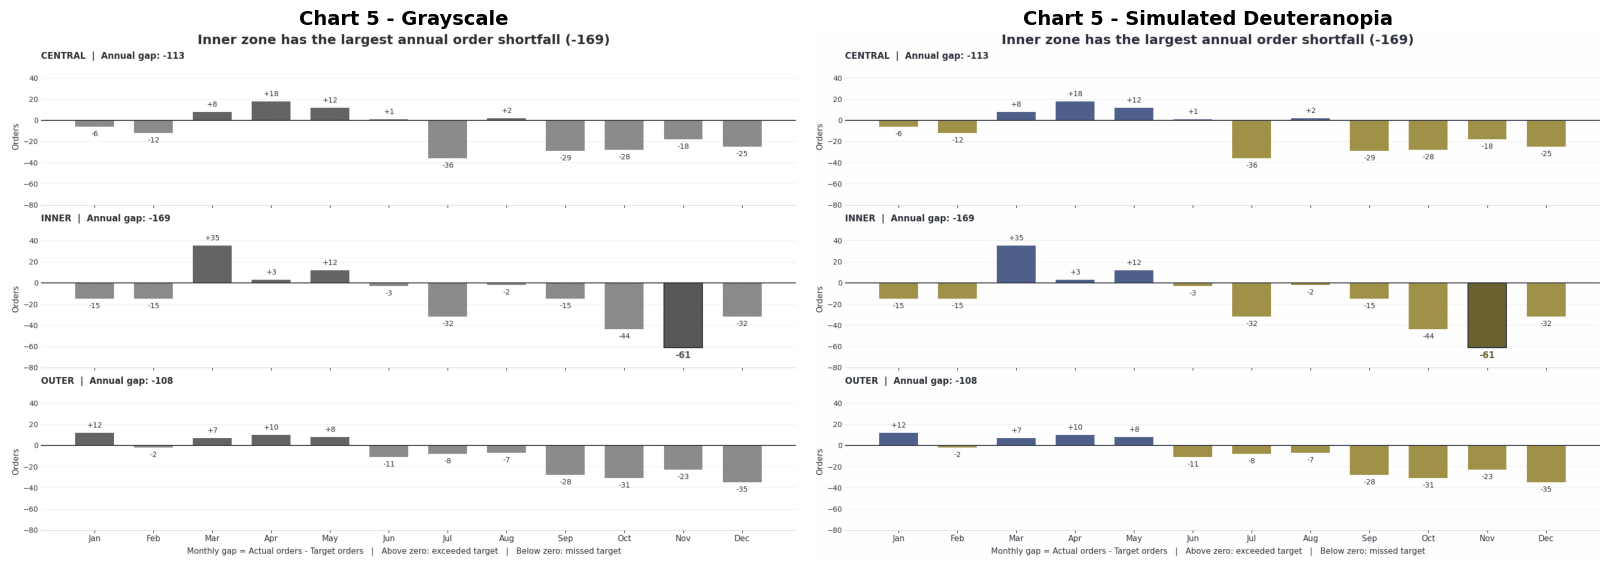

In [3]:

# ==================================================
# TASK 3 - CHART 5 ACCESSIBILITY TEST
# Grayscale + simulated deuteranopia
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# Capture the redesigned Chart 5
fig5.canvas.draw()
rgb5 = np.asarray(
    fig5.canvas.buffer_rgba()
)[..., :3].astype(float) / 255.0

# 1. Grayscale simulation (sRGB luminance)
linear5 = np.where(
    rgb5 <= 0.04045,
    rgb5 / 12.92,
    ((rgb5 + 0.055) / 1.055) ** 2.4
)

luminance5 = (
    0.2126 * linear5[..., 0]
    + 0.7152 * linear5[..., 1]
    + 0.0722 * linear5[..., 2]
)

gray5 = np.where(
    luminance5 <= 0.0031308,
    12.92 * luminance5,
    1.055 * luminance5 ** (1 / 2.4) - 0.055
)

# 2. Deuteranopia simulation
matrix5 = np.array([
    [0.367322, 0.860646, -0.227968],
    [0.280085, 0.672501, 0.047413],
    [-0.011820, 0.042940, 0.968881]
])

sim_linear5 = np.clip(
    linear5 @ matrix5.T, 0, 1
)

deuter5 = np.where(
    sim_linear5 <= 0.0031308,
    12.92 * sim_linear5,
    1.055 * sim_linear5 ** (1 / 2.4) - 0.055
)

# Display both tests
fig_test5, ax_test5 = plt.subplots(
    1, 2, figsize=(16, 6),
    constrained_layout=True
)

ax_test5[0].imshow(
    np.clip(gray5, 0, 1),
    cmap="gray",
    vmin=0,
    vmax=1
)
ax_test5[0].set_title(
    "Chart 5 - Grayscale",
    fontsize=14, fontweight="bold"
)

ax_test5[1].imshow(
    np.clip(deuter5, 0, 1)
)
ax_test5[1].set_title(
    "Chart 5 - Simulated Deuteranopia",
    fontsize=14, fontweight="bold"
)

for ax in ax_test5:
    ax.axis("off")

plt.show()


### Chart 5 – Accessibility Test Results

**Grayscale test:** Positive and negative gaps remain distinguishable through their positions relative to the zero baseline and signed numerical labels.

**Deuteranopia test:** The redesigned blue–orange palette remains visually distinguishable in the simulation. Readers can also use bar direction and numerical values to interpret performance.

**Accessibility improvements:** The original red–green encoding was replaced with blue and orange. Direct signed labels and a shared zero baseline were added to reduce dependence on colour.

**Conclusion:** Both simulations preserve the main information. Inner's November shortfall (−61 orders) remains identifiable, although small labels may be harder to read when the figure is reduced in size.

### Chart 6 · Basket by tier
*Task:* ...  *Why this chart:* ...

In [4]:
# TODO: write your code here

In [5]:
# TODO: write your code here

*Check: every number in your six titles, with the output that proves it.*

## Task 3 · Test for every reader
Greyscale and deuteranopia versions of all six redesigns. Then: one change you made because of a test.

In [6]:
# TODO: write your code here

*The change we made because of a test, and why:*

## Task 4 · Perception experiment
### 4.1 Your stimulus sheet
Use **your team number** from the LMS list. Print the sheet (or put it in a form). Do not show the true values to anyone.

In [7]:
# truth = make_stimuli(team_number=__)
# print(truth)
# TODO: write your code here

### 4.2 Protocol (fill in before you collect)
Who (≥ 15 people not in this course), where, when, how you avoid helping them, how you record answers, consent, no names.

### 4.3 Your answers
Save your answers as `experiment_answers.csv` with the columns
`respondent, encoding, item, true, judged, collector` (one row per estimate; `collector` = the student ID of the team
member who collected it). Upload it next to the notebook.

In [8]:
# answers = pd.read_csv("experiment_answers.csv")
# answers["log_error"] = np.log2(np.abs(answers["judged"] - answers["true"]) + 1 / 8)   # Cleveland & McGill (1984)
# print(answers.groupby("encoding")["log_error"].agg(["mean", "count"]).round(2))

In [9]:
# Task 4.3: compute log_error for your own answers and summarise it by encoding
# TODO: write your code here

### 4.4 Result chart

In [10]:
# TODO: write your code here

### 4.5 Interpretation (at most 150 words)
Does your result agree with Cleveland & McGill (1984)? Which item was hardest, and why? Two limitations of your experiment.

## Task 5 · The one-page figure
Three panels, one action title, consistent colours with Tasks 2-3.

In [11]:
# Task 5: one figure, three panels, one action title
# TODO: write your code here

## Task 6 · Team and AI
| Member | What they did | Answers collected (Task 4) | Share of work |
|---|---|---|---|
| | | | |

In [12]:
AI_USE = """
Tool(s) used:
What we asked:
What we checked or changed ourselves:
"""
print(AI_USE)


Tool(s) used:
What we asked:
What we checked or changed ourselves:

